In [1]:
import numpy as np
import matplotlib.pyplot as plt

T = np.array([0, 8, 16, 24, 32, 40], dtype=float)
O = np.array([14.621, 11.843, 9.870, 8.418, 7.305, 6.413], dtype=float)


In [ ]:
def newton_divided_diff_coeffs(x, y):

    n = len(x)
    F = np.zeros((n, n))
    F[:, 0] = y  

    for j in range(1, n):         
        for i in range(n - j):    
            F[i, j] = (F[i + 1, j - 1] - F[i, j - 1]) / (x[i + j] - x[i])

    coeffs = F[0, :] 
    return coeffs, F


def newton_eval(coeffs, x, Tq):
    
    n = len(coeffs)
    Tq = np.asarray(Tq, dtype=float)
    P = np.full_like(Tq, coeffs[-1])
    for k in range(n - 2, -1, -1):
        P = P * (Tq - x[k]) + coeffs[k]
    return P


ncoeffs, F = newton_divided_diff_coeffs(T, O)

print("Divided Difference Table (rows = i, cols = order j):")
n = len(T)
for i in range(n):
    row = "  ".join(f"{F[i,j]: .8f}" for j in range(n - i))
    print(f"i={i}: {row}")

print("\nNewton coefficients b0..b5:")
for k, c in enumerate(ncoeffs):
    print(f"  b{k} = {c:.8f}")


Divided Difference Table (rows = i, cols = order j):
i=0:  14.62100000  -0.34725000   0.00628906  -0.00009245   0.00000104  -0.00000001
i=1:  11.84300000  -0.24662500   0.00407031  -0.00005924   0.00000065
i=2:  9.87000000  -0.18150000   0.00264844  -0.00003841
i=3:  8.41800000  -0.13912500   0.00172656
i=4:  7.30500000  -0.11150000
i=5:  6.41300000

Newton coefficients b0..b5:
  b0 = 14.62100000
  b1 = -0.34725000
  b2 = 0.00628906
  b3 = -0.00009245
  b4 = 0.00000104
  b5 = -0.00000001


In [ ]:

print("Check at data points:")
for Ti, Oi in zip(T, O):
    Pval = newton_eval(ncoeffs, T, Ti)
    print(f"  T={Ti:5.1f}  O_data={Oi:8.4f}  P(T)={Pval:8.4f}")


Check at data points:
  T=  0.0  O_data= 14.6210  P(T)= 14.6210
  T=  8.0  O_data= 11.8430  P(T)= 11.8430
  T= 16.0  O_data=  9.8700  P(T)=  9.8700
  T= 24.0  O_data=  8.4180  P(T)=  8.4180
  T= 32.0  O_data=  7.3050  P(T)=  7.3050
  T= 40.0  O_data=  6.4130  P(T)=  6.4130


In [ ]:
m = n - 1          
nunk = 3 * m        

A = np.zeros((nunk, nunk))
rhs = np.zeros(nunk)

def idx(i, which):
    """index of a_i,b_i,c_i (i is 1-based segment number) in the unknown vector"""
    base = 3 * (i - 1)
    return base + {'a': 0, 'b': 1, 'c': 2}[which]

row = 0


for i in range(1, m + 1):
    Ti = T[i - 1]
    A[row, idx(i, 'a')] = Ti**2
    A[row, idx(i, 'b')] = Ti
    A[row, idx(i, 'c')] = 1.0
    rhs[row] = O[i - 1]
    row += 1


for i in range(1, m + 1):
    Tip1 = T[i]
    A[row, idx(i, 'a')] = Tip1**2
    A[row, idx(i, 'b')] = Tip1
    A[row, idx(i, 'c')] = 1.0
    rhs[row] = O[i]
    row += 1

for i in range(2, m + 1):
    Ti = T[i - 1]  
    A[row, idx(i - 1, 'a')] = 2 * Ti
    A[row, idx(i - 1, 'b')] = 1.0
    A[row, idx(i, 'a')] = -2 * Ti
    A[row, idx(i, 'b')] = -1.0
    rhs[row] = 0.0
    row += 1
A[row, idx(1, 'a')] = 1.0
rhs[row] = 0.0
row += 1

assert row == nunk
print(f"System assembled: {A.shape[0]} equations, {A.shape[1]} unknowns")


System assembled: 15 equations, 15 unknowns


In [ ]:
def gauss_elimination(A_in, b_in):
   
    A = A_in.copy()
    b = b_in.copy()
    n = len(b)
    Aug = np.hstack([A, b.reshape(-1, 1)])

    for k in range(n - 1):
        p = np.argmax(np.abs(Aug[k:, k])) + k   
        if p != k:
            Aug[[k, p], :] = Aug[[p, k], :]
        for i in range(k + 1, n):
            factor = Aug[i, k] / Aug[k, k]
            Aug[i, k:] -= factor * Aug[k, k:]

    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (Aug[i, -1] - np.dot(Aug[i, i + 1:n], x[i + 1:n])) / Aug[i, i]
    return x


spline_coeffs = gauss_elimination(A, rhs)

print("Quadratic spline coefficients (a_i, b_i, c_i) \n")
for i in range(1, m + 1):
    a = spline_coeffs[idx(i, 'a')]
    b = spline_coeffs[idx(i, 'b')]
    c = spline_coeffs[idx(i, 'c')]
    print(f"Segment {i}  [T in {T[i-1]:.0f},{T[i]:.0f}]:  "
          f"S{i}(T) = {a:.8f} T^2 + {b:.8f} T + {c:.8f}")


coeffs_check = np.linalg.solve(A, rhs)
print("\nMax difference vs numpy.linalg.solve:", np.max(np.abs(spline_coeffs - coeffs_check)))


Quadratic spline coefficients (a_i, b_i, c_i) for each segment i=1..5:

Segment 1  [T in 0,8]:  S1(T) = -0.00000000 T^2 + -0.34725000 T + 14.62100000
Segment 2  [T in 8,16]:  S2(T) = 0.01257813 T^2 + -0.54850000 T + 15.42600000
Segment 3  [T in 16,24]:  S3(T) = -0.00443750 T^2 + -0.00400000 T + 11.07000000
Segment 4  [T in 24,32]:  S4(T) = 0.00973437 T^2 + -0.68425000 T + 19.23300000
Segment 5  [T in 32,40]:  S5(T) = -0.00628125 T^2 + 0.34075000 T + 2.83300000

Max difference vs numpy.linalg.solve: 4.3076653355456074e-14


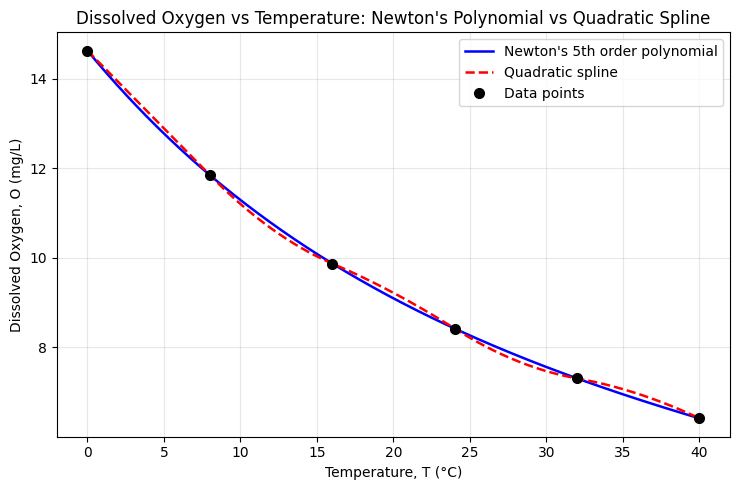

In [ ]:
def eval_spline(Tq, T_nodes, coeffs):
    
    mseg = len(T_nodes) - 1
    out = np.zeros_like(Tq)
    for j, Tv in enumerate(Tq):
        i = np.searchsorted(T_nodes, Tv, side='right') - 1
        i = min(max(i, 0), mseg - 1)
        a, b, c = coeffs[3*i], coeffs[3*i+1], coeffs[3*i+2]
        out[j] = a*Tv**2 + b*Tv + c
    return out


Tfine = np.linspace(0, 40, 500)
Pnewton = newton_eval(ncoeffs, T, Tfine)
Pspline = eval_spline(Tfine, T, spline_coeffs)

plt.figure(figsize=(7.5, 5))
plt.plot(Tfine, Pnewton, 'b-', linewidth=1.8, label="Newton's 5th order polynomial")
plt.plot(Tfine, Pspline, 'r--', linewidth=1.8, label="Quadratic spline")
plt.plot(T, O, 'ko', markersize=7, label="Data points")
plt.xlabel("Temperature, T (°C)")
plt.ylabel("Dissolved Oxygen, O (mg/L)")
plt.title("Dissolved Oxygen vs Temperature: Newton's Polynomial vs Quadratic Spline")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("q1d_plot.png", dpi=200)
plt.show()
